In [2]:
%pip install opensim
import opensim as osim
print(osim.__version__)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import opensim as osim


Note: you may need to restart the kernel to use updated packages.
4.6


In [3]:
import os
import opensim as osim

chemin = "/Users/lucas1/Desktop/Formation_OpenSim/01_modele/Rajagopal2016.osim"
print("Version OpenSim :", osim.GetVersion())
print("Le fichier existe :", os.path.exists(chemin))
print("Lisible :", os.access(chemin, os.R_OK))
if os.path.exists(chemin):
    print("Taille :", os.path.getsize(chemin), "octets  (attendu ≈ 874 820)")
print("Contenu du dossier :", os.listdir(os.path.dirname(chemin)))

try:
    osim.Model(chemin)
    print("Modèle chargé !")
except Exception as e:
    print("MESSAGE COMPLET :", e)

Version OpenSim : 4.6-2026-06-22-85aaf64
Le fichier existe : True
Lisible : True
Taille : 874820 octets  (attendu ≈ 874 820)
Contenu du dossier : ['01_modele_SOLUTIONS.ipynb', '.DS_Store', 'outils_opensim.py', '01_modele_EXERCICES.ipynb', '__pycache__', 'opensim.log', 'Rajagopal2016.osim']
[info] Updating Model file from 40000 to latest format...
Modèle chargé !
[info] Loaded model Rajagopal2016 from file /Users/lucas1/Desktop/Formation_OpenSim/01_modele/Rajagopal2016.osim
[warning] Couldn't find file 'r_pelvis.vtp'.
[warning] Couldn't find file 'l_pelvis.vtp'.
[warning] Couldn't find file 'sacrum.vtp'.
[warning] Couldn't find file 'r_femur.vtp'.
[warning] Couldn't find file 'r_tibia.vtp'.
[warning] Couldn't find file 'r_fibula.vtp'.
[warning] Couldn't find file 'r_patella.vtp'.
[warning] Couldn't find file 'r_talus.vtp'.
[warning] Couldn't find file 'r_foot.vtp'.
[warning] Couldn't find file 'r_bofoot.vtp'.
[warning] Couldn't find file 'l_femur.vtp'.
[warning] Couldn't find file 'l_ti

In [4]:
import glob, os
maison = os.path.expanduser("~")          # = /Users/lucas1
trouves = glob.glob(maison + "/**/01_modele/Rajagopal2016.osim", recursive=True)
print(trouves)

os.chdir(os.path.dirname(trouves[0]))     # va dans le dossier trouvé
print(os.getcwd())
modele = osim.Model("Rajagopal2016.osim")
etat = modele.initSystem()
print("Masse :", round(modele.getTotalMass(etat), 1), "kg")

['/Users/lucas1/Desktop/Formation_OpenSim/01_modele/Rajagopal2016.osim', '/Users/lucas1/Library/Containers/com.apple.dp.PrivateFederatedLearning.DPMLRuntimePluginClassB/Data/Desktop/Formation_OpenSim/01_modele/Rajagopal2016.osim', '/Users/lucas1/Library/Containers/com.apple.ScreenSaver.Engine.legacyScreenSaver/Data/Desktop/Formation_OpenSim/01_modele/Rajagopal2016.osim', '/Users/lucas1/Library/Containers/com.apple.freeform/Data/Desktop/Formation_OpenSim/01_modele/Rajagopal2016.osim', '/Users/lucas1/Library/Containers/com.apple.settings-intents.TransferResetIntents/Data/Desktop/Formation_OpenSim/01_modele/Rajagopal2016.osim', '/Users/lucas1/Library/Containers/com.apple.generativeassistanttools.settingsextension.GenerativeAssistantSettingsExtension/Data/Desktop/Formation_OpenSim/01_modele/Rajagopal2016.osim', '/Users/lucas1/Library/Containers/com.apple.Network-Settings.extension/Data/Desktop/Formation_OpenSim/01_modele/Rajagopal2016.osim', '/Users/lucas1/Library/Containers/com.apple.Soni

In [5]:
# __ 2 : Inventaire 
print("Corps : ", modele.getBodySet().getSize())
print("Articulation :", modele.getJointSet().getSize())
print("Coordonnées :", modele.getCoordinateSet().getSize())
print("Muscle:", modele.getMuscles().getSize())
print("Marqueurs :", modele.getMarkerSet().getSize())

Corps :  22
Articulation : 22
Coordonnées : 39
Muscle: 80
Marqueurs : 66


In [6]:
# -- 3. Les coordonnées
cs = modele.getCoordinateSet()
for i in range(cs.getSize()):
    c = cs.get(1)
    rot = c.getMotionType() == 1
    f = np.rad2deg if rot else (lambda x: x)
print(f"{c.getName():22s} {'rotation' if rot else 'autre '} [{f(c.getRangeMin()):7.1f} ; {f(c.getRangeMax()):7.1f}]"
f" verrouillée={c.getDefaultLocked()}")

pelvis_list            rotation [  -90.0 ;    90.0] verrouillée=False


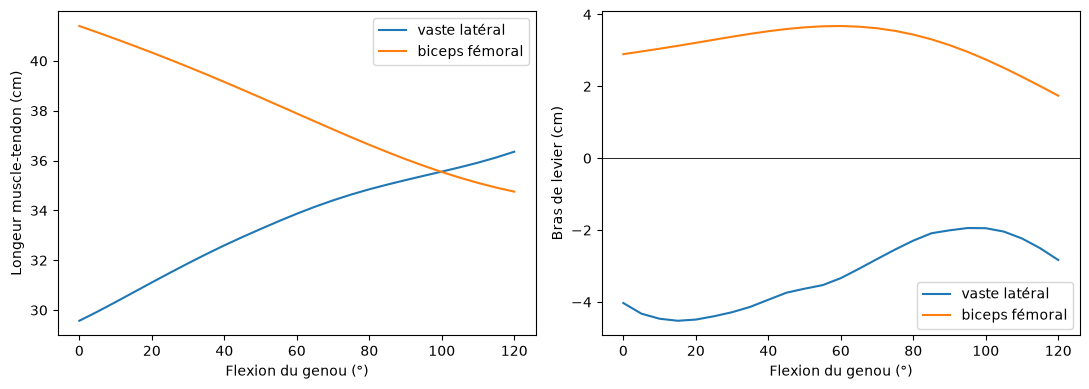

In [7]:
# 4) Mettre le modèle dans une posture 
genou = cs.get("knee_angle_r")
vaste, biceps = modele.getMuscles().get("vaslat_r"), modele.getMuscles().get("bflh_r")
angles = np.arange(0, 121, 5)
L_v, L_b, r_v, r_b = [], [], [], []
for a in angles: 
    genou.setValue(etat, np.deg2rad(a))
    modele.realizePosition(etat)
    L_v.append(vaste.getLength(etat))
    L_b.append(biceps.getLength(etat))
    r_v.append(vaste.computeMomentArm(etat, genou))
    r_b.append(biceps.computeMomentArm(etat, genou))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(angles, np.array(L_v) * 100, label="vaste latéral")
ax[0].plot(angles, np.array(L_b) * 100, label="biceps fémoral")
ax[0].set_xlabel("Flexion du genou (°)")
ax[0].set_ylabel("Longeur muscle-tendon (cm)")
ax[0].legend()

ax[1].plot(angles, np.array(r_v) * 100, label="vaste latéral")
ax[1].plot(angles, np.array(r_b) * 100,label="biceps fémoral")
ax[1].axhline(0, color="k", lw=0.6)
ax[1].set_xlabel("Flexion du genou (°)")
ax[1].set_ylabel("Bras de levier (cm)"); ax[1].legend()
plt.tight_layout()
plt.show()








Flexion de genou 0° = jambe tendu à 120° => voit les deux muscles
Vaste latéral = quadriceps 
biceps fémoral = ischio 

Graphique à droite 
- Allongement vaste latéral = étirement
- Raccourssissement biceps fémoral = actif 
==> on est bien sur une flexion, pendant l'amortissement, le genou se plie => W excentrique 

Graphique à gauche
Moment = Force x bras de levier
- Biceps fémoral = bras de levier positif =>  flechit genou
- Vaste latéral = bras de levier negatif => genou qui s'étend

Le bras de levier est la pente de la courbe de longueur 
r = −dL/dθ (pente de la longueur, signe inversé)

In [8]:
# 5) Les param§tres d'un muscle (modèle de Hill)
for nom in ["soleus_r", "gasmed_r", "vaslat_r", "recfem_r", "glmax2_r","vaslat_r", "recfem_r", "glmax2_r", "bflh_r", "tibant_r"]:
    m = modele.getMuscles().get(nom)
    print(f"{nom:9s} Fmax={m.getMaxIsometricForce():6.0f} N L0={m.getOptimalFiberLength()*100:4.1f} cm "
f"Ltendon={m.getTendonSlackLength()*100:4.1f} cm ratio tendon/fibre={m.getTendonSlackLength()/m.getOptimalFiberLength():4.1f}")



soleus_r  Fmax=  6195 N L0= 4.4 cm Ltendon=27.7 cm ratio tendon/fibre= 6.3
gasmed_r  Fmax=  3116 N L0= 5.1 cm Ltendon=39.9 cm ratio tendon/fibre= 7.8
vaslat_r  Fmax=  5149 N L0= 9.9 cm Ltendon=22.1 cm ratio tendon/fibre= 2.2
recfem_r  Fmax=  2192 N L0= 7.6 cm Ltendon=44.8 cm ratio tendon/fibre= 5.9
glmax2_r  Fmax=  1406 N L0=15.7 cm Ltendon= 6.8 cm ratio tendon/fibre= 0.4
vaslat_r  Fmax=  5149 N L0= 9.9 cm Ltendon=22.1 cm ratio tendon/fibre= 2.2
recfem_r  Fmax=  2192 N L0= 7.6 cm Ltendon=44.8 cm ratio tendon/fibre= 5.9
glmax2_r  Fmax=  1406 N L0=15.7 cm Ltendon= 6.8 cm ratio tendon/fibre= 0.4
bflh_r    Fmax=  1313 N L0= 9.8 cm Ltendon=32.5 cm ratio tendon/fibre= 3.3
tibant_r  Fmax=  1227 N L0= 6.8 cm Ltendon=24.0 cm ratio tendon/fibre= 3.5


Défition des termes 
- Fmax = force max isométrique
- L0 = longueur des fibres => où on a force max => optimale
- L tendon = longueur tendon commence à transmettre la force 
- Ration T/L: qui absorbe les changements longeur => caapcité élastique 

Gastrocnemien + solaire => ratio élevé (6-8) = energie élastique 


In [9]:
# 6) Défis 
def moment_max(nom_muscle, nom_coord):
    m = modele.getMuscles().get(nom_muscle)
    modele.realizePosition(etat)
    return m.getMaxIsometricForce() * abs(m.computeMomentArm(etat, cs.get(nom_coord)))

for flex in (0,90):
    cs.get("knee_angle_r").setValue(etat, np.deg2rad(flex))
    print(f"genou {flex:3d}° : soléaire {moment_max('soleus_r', 'ankle_angle_r'):5.0f} N·m | "
f"gastrocnémien médial {moment_max('gasmed_r', 'ankle_angle_r'):5.0f} N·m")




genou   0° : soléaire   256 N·m | gastrocnémien médial   134 N·m
genou  90° : soléaire   256 N·m | gastrocnémien médial   133 N·m


In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import opensim as osim
from outils_opensim import * # lire_sto, lire_trc, ecrire_trc, normaliser, evenements, rms
osim.Logger.setLevelString("error") # OpenSim n'affiche que les erreurs
print("OpenSim", osim.GetVersion(), "| dossier :", os.getcwd())

OpenSim 4.6-2026-06-22-85aaf64 | dossier : /Users/lucas1/Desktop/Formation_OpenSim/01_modele


In [11]:
import os
os.chdir("/Users/lucas1/Desktop/Formation_OpenSim/02_IK")
print(os.getcwd())
print(os.path.exists("Course_marqueurs.trc"))   # doit afficher True

/Users/lucas1/Desktop/Formation_OpenSim/02_IK
True


54 marqueurs, 421 images, 200 Hz


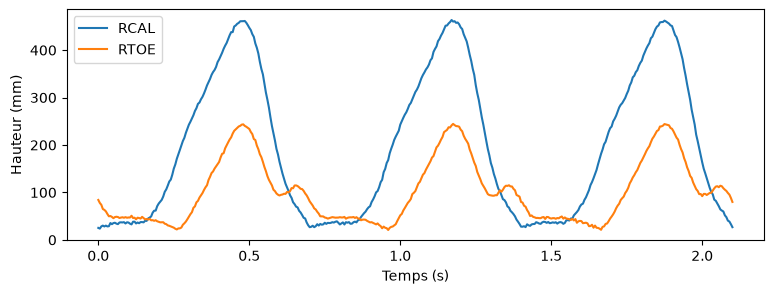

In [12]:

# -- 1 inspecter les marqueurs 
t, noms, P = lire_trc("Course_marqueurs.trc")
print(len(noms), "marqueurs,", len(t), "images,", round(1 / (t[1] - t[0])), "Hz")
plt.figure(figsize=(9,3))
for n in ["RCAL", "RTOE"]:
    plt.plot(t, P[:, noms.index(n), 1], label=n)
plt.xlabel("Temps (s)")
plt.ylabel("Hauteur (mm)")
plt.legend()
plt.show()


Lecture de la foulée 0.7 => 1.4 s
- ≈ 0.70s = contact par le talon (RCAL bas 30mm; RTOE plus haut 100mm) => montre bien une attaque talon 
- 0.75s - 0.85s = pied à pas, deux marqueurs bas 
- 0.87s = talon décolle avant ortiels
- 0.94s : decollage ortel => fin d'appuis 
- 1.18s : oscillation, pic du tallon 460mm, genou très flechi ≈ 100°
- 1.35s : petite bosse RTOE => pied se relève avant le contact suivant 

Jamais hauteur = 0 car maruqueurs sur la peau/chaussure 
course assez réguliere 

In [13]:
# -- 2 Lancer l'IK
ik = osim.InverseKinematicsTool("Course_Setup_IK.xml")
ik.run()
err = lire_sto("resultats_IK/Course_IK_ik_marker_errors.sto")
print(f"RMS moyen {err.marker_error_RMS.mean()*1000:.1f} mm | max {err.marker_error_max.max()*1000:.1f} mm")


               MODEL: Rajagopal2016
         coordinates: 39
              forces: 97
           actuators: 97
             muscles: 80
            analyses: 0
              probes: 0
              bodies: 22
              joints: 22
         constraints: 2
             markers: 66
         controllers: 0
  contact geometries: 0
misc modelcomponents: 0
RMS moyen 2.9 mm | max 9.7 mm


RMS = 0.29 < 1-2cm => donc excellent 
Max = 0.97 < 2-4cm => donc excellent 

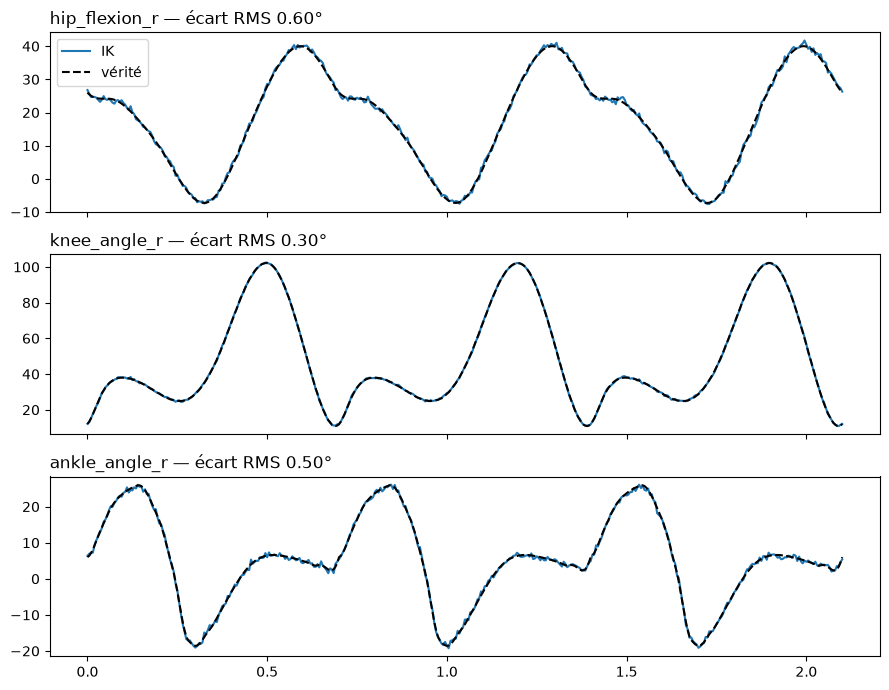

In [14]:
# -- 3 Comparer les flexions à la vérité 
ang, vrai = lire_sto("Course_IK.mot"), lire_sto("Course_verite.mot")
fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
for ax, c in zip(axes, ["hip_flexion_r", "knee_angle_r", "ankle_angle_r"]):
    ax.plot(ang.time, ang[c], label="IK"); ax.plot(vrai.time, vrai[c], "k--", label="vérité")
    ax.set_title(f"{c} — écart RMS {rms(np.interp(vrai.time, ang.time, ang[c]), vrai[c]):.2f}°", loc="left")
axes[0].legend(); plt.tight_layout(); plt.show()

Interprétation 
3 courbes se superpose : ecart RMS < 1°
Hanche la moins précise 

In [15]:
# -- 4. Expérience : tous les poids à 1
ik2 = osim.InverseKinematicsTool("Course_Setup_IK.xml")
taches = ik2.getIKTaskSet()
for i in range(taches.getSize()):
    taches.get(i).setWeight(1.0)
ik2.setName("IK_poids1")
ik2.setOutputMotionFileName("IK_poids1.mot")
ik2.run()

a2 = lire_sto("IK_poids1.mot")
for c in ["hip_flexion_r", "knee_angle_r", "ankle_angle_r"]:
    print(f"{c:15s} poids réglés {rms(np.interp(vrai.time, ang.time, ang[c]), vrai[c]):.2f}° | poids=1 {rms(np.interp(vrai.time, a2.time, a2[c]), vrai[c]):.2f}°")



               MODEL: Rajagopal2016
         coordinates: 39
              forces: 97
           actuators: 97
             muscles: 80
            analyses: 0
              probes: 0
              bodies: 22
              joints: 22
         constraints: 2
             markers: 66
         controllers: 0
  contact geometries: 0
misc modelcomponents: 0
hip_flexion_r   poids réglés 0.60° | poids=1 0.63°
knee_angle_r    poids réglés 0.30° | poids=1 0.29°
ankle_angle_r   poids réglés 0.50° | poids=1 0.54°


In [16]:
# -- 5 : Expérience : sans les marqueurs du bassin 
ik3 = osim.InverseKinematicsTool("Course_Setup_IK.xml")
for n in ["RASI", "LASI", "RPSI", "LPSI"]:
    ik3.getIKTaskSet().get(n).setApply(False)
ik3.setName("IK_sans_bassin.mot")
ik3.setOutputMotionFileName("IK_sans_bassin.mot")
ik3.run()

a3 = lire_sto("IK_sans_bassin.mot")
for c in ["pelvis_tilt", "hip_flexion_r", "knee_angle_r"]:
    print(f"{c:15s} écart à la vérité : {rms(np.interp(vrai.time, a3.time, a3[c]), vrai[c]):.2f}°")

# -- 6. Exporter un tableau des flexions (CVS)
ang[["time", "hip_flexion_r", "knee_angle_r", "ankle_angle_r"]].to_csv("Flexions_IK.csv", sep=";", decimal=",", index=False)
print("flexions_IK.csv écrit")


               MODEL: Rajagopal2016
         coordinates: 39
              forces: 97
           actuators: 97
             muscles: 80
            analyses: 0
              probes: 0
              bodies: 22
              joints: 22
         constraints: 2
             markers: 66
         controllers: 0
  contact geometries: 0
misc modelcomponents: 0
pelvis_tilt     écart à la vérité : 1.74°
hip_flexion_r   écart à la vérité : 2.20°
knee_angle_r    écart à la vérité : 0.60°
flexions_IK.csv écrit


In [17]:
# Étape 3 – Dynamique inverse (ID)
# ── 1. Détecter les foulées du pied droit
os.chdir("/Users/lucas1/Desktop/Formation_OpenSim/03_ID")

grf = lire_sto("Course_GRF.mot")
contacts, decollages = evenements(grf, "r")
print("contacts :", contacts, "\ndécollages :", decollages)

contacts : [0.03 0.7  1.4  2.1 ] 
décollages : [0.245 0.945 1.645]



               MODEL: Rajagopal2016
         coordinates: 39
              forces: 97
           actuators: 97
             muscles: 80
            analyses: 0
              probes: 0
              bodies: 22
              joints: 22
         constraints: 2
             markers: 66
         controllers: 0
  contact geometries: 0
misc modelcomponents: 0


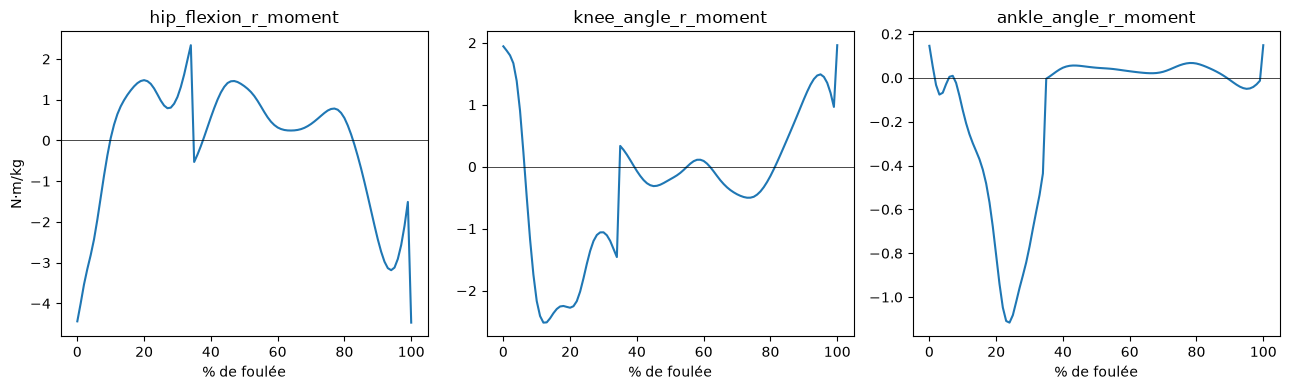

In [18]:
# ── 2. Lancer l'ID et tracer les moments (N·m/kg), normalisés de 0 à 100 % de la foulée
os.chdir("/Users/lucas1/Desktop/Formation_OpenSim/03_ID")   # si ce n'est pas déjà fait
MASSE = 75.3                                                # kg

idt = osim.InverseDynamicsTool("Course_Setup_ID.xml")
idt.run()                                                   # ← LE CALCUL
mom = lire_sto("resultats_ID/Course_ID.sto")

a, b = contacts[1], contacts[2]       # 2e → 3e contact du pied droit (étape 1)
pct = np.linspace(0, 100, 101)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, c in zip(axes, ["hip_flexion_r_moment", "knee_angle_r_moment", "ankle_angle_r_moment"]):
    ax.plot(pct, normaliser(mom.time, mom[c] / MASSE, a, b))
    ax.axhline(0, color="k", lw=0.5)
    ax.set_title(c)
    ax.set_xlabel("% de foulée")
axes[0].set_ylabel("N·m/kg")
plt.tight_layout()
plt.show()





Interprétation 
- Hanche : grande extension en fin d'oscillation / Ischio et fessier freinent la jmabe lancée vers l'avant 
- Genou : extension debut d'appuis, flehcissuer en find'oscillation, quadriceps = amortissement excentrique 
- Cheville : negatif durant l'appuis, triceps sural freine le tibia et propulse




               MODEL: Rajagopal2016
         coordinates: 39
              forces: 97
           actuators: 97
             muscles: 80
            analyses: 0
              probes: 0
              bodies: 22
              joints: 22
         constraints: 2
             markers: 66
         controllers: 0
  contact geometries: 0
misc modelcomponents: 0

               MODEL: Rajagopal2016
         coordinates: 39
              forces: 97
           actuators: 97
             muscles: 80
            analyses: 0
              probes: 0
              bodies: 22
              joints: 22
         constraints: 2
             markers: 66
         controllers: 0
  contact geometries: 0
misc modelcomponents: 0

               MODEL: Rajagopal2016
         coordinates: 39
              forces: 97
           actuators: 97
             muscles: 80
            analyses: 0
              probes: 0
              bodies: 22
              joints: 22
         constraints: 2
             markers: 66
    

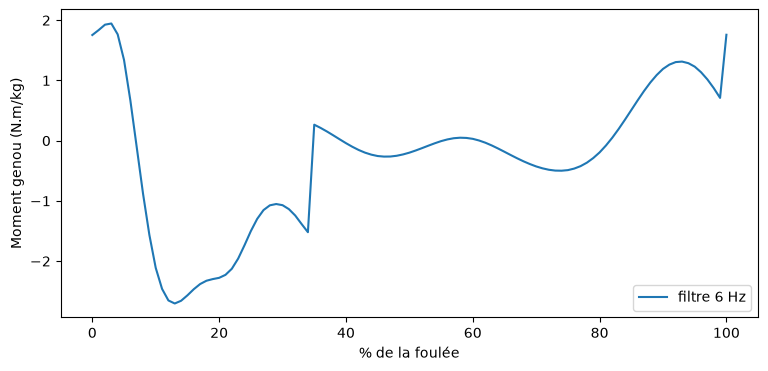

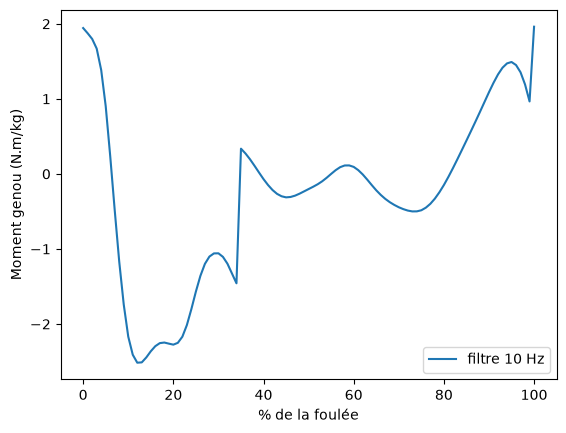

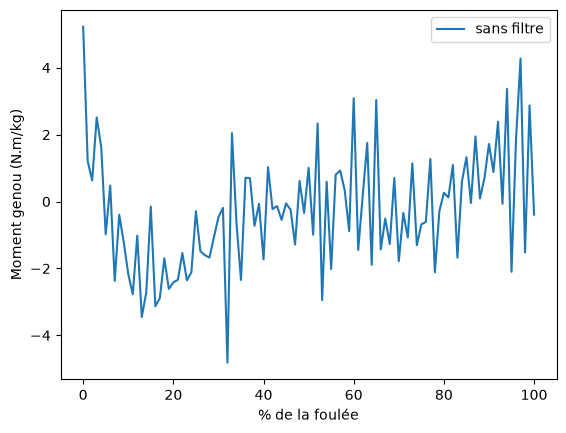

In [19]:
# -- 3. Effet du filtrage 
resultats = {}
for fc in (6, 10, -1):
    t2 = osim.InverseDynamicsTool("Course_Setup_ID.xml")
    t2.setLowpassCutoffFrequency(fc)
    t2.setOutputGenForceFileName(f"ID_fc{fc}.sto")
    t2.run()
    resultats[fc] = lire_sto(f"resultats_ID/ID_fc{fc}.sto")
plt.figure(figsize=(9,4))
for fc, d in resultats.items():
    plt.plot(pct, normaliser(d.time, d.knee_angle_r_moment / MASSE, a, b), label=f"filtre {fc} Hz" if fc > 0 else "sans filtre")
    plt.legend()
    plt.xlabel("% de la foulée")
    plt.ylabel("Moment genou (N.m/kg)")
    plt.show()




Interprétation: 
- Utilisation du filtre permet de lisser le signal et le rendre plus visible
- Deux filtre 6hz / 10Hz =< presque les mêmes courbes
0-5% = moment fléchisseur bref au contact 
5-30% = grand moment extensueur, quadriceps amortissement
80-100% = moment flehcissuer, ischio-jambier freinent la jambe avant le contact 



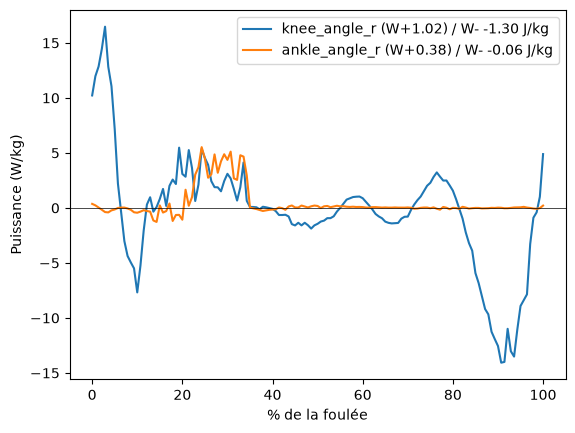

In [20]:
# -- 4. Puissance articulaire 
ang = lire_sto("Course_IK.mot")
for art in ["knee_angle_r", "ankle_angle_r"]:
    theta = np.deg2rad(normaliser(ang.time, ang[art], a, b, n=141))
    tt = np.linspace(a, b, 141)
    vitesse = np.gradient(theta, tt)
    tau = normaliser(resultats[10].time, resultats[10][art + "_moment"], a, b, n=141)
    P = tau * vitesse / MASSE
    W_pos = np.trapezoid(np.clip(P,0, None), tt)
    W_neg = np.trapezoid(np.clip(P, None, 0), tt)
    plt.plot(np.linspace(0,100,141),P,label=f"{art} (W+{W_pos:.2f}) / W- {W_neg:.2f} J/kg")
plt.axhline(0, color="k", lw=0.5)
plt.legend()
plt.ylabel("Puissance (W/kg)")
plt.xlabel("% de la foulée")
plt.show()


In [21]:
# --5. les résiduels 
d = resultats[10]
pic_grf = grf.ground_force_r_vx.max()
r = d.pelvis_ty_force.abs()
print(f"résiduel vertical moyen {r.mean():.0f} N ({100*r.mean()/pic_grf:.1f} % du pic) | max {r.max():.0f} N ({100*r.max()/pic_grf:.1f} %)")

résiduel vertical moyen 97 N (24.6 % du pic) | max 657 N (167.4 %)


In [22]:
# Etape 4 - optimsation statique 
# --1. Lancer la S0
os.chdir("/Users/lucas1/Desktop/Formation_OpenSim/04_SO")
print(os.path.exists("Course_Setup_SO.xml"))   # doit afficher True
so = osim.AnalyzeTool("Course_Setup_SO.xml")
so.run()

act = lire_sto("resultats_SO/Course_SO_StaticOptimization_activation.sto")
frc = lire_sto("resultats_SO/Course_SO_StaticOptimization_force.sto")

print(act.shape)

True
[error] Model unable to assemble: AssemblySolver::assemble() Failed: SimTK Exception thrown at Assembler.cpp:897:
  Method Assembler::assemble() failed because:
Unable to achieve required assembly error tolerance.
Assembly error tolerance achieved: 9.6025685138172016e-09 required: 1e-10..Model relaxing constraints and trying again.
(141, 118)


/var/folders/hq/bv4dnz1d133by50wj_29tgdw0000gq/T/ipykernel_5754/2520165747.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


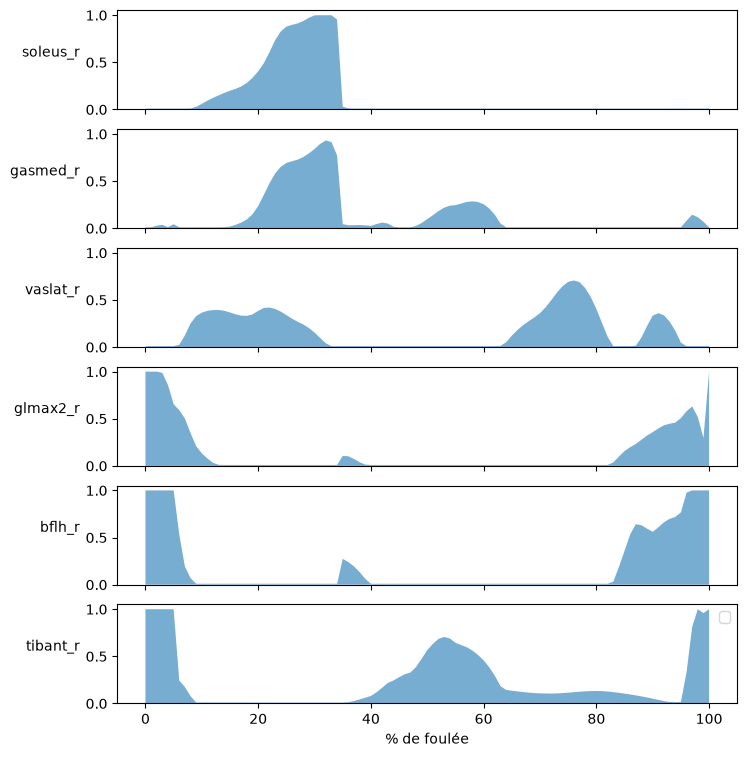

In [23]:
# --2. Activations de 6 muscles clé 
muscles = ["soleus_r", "gasmed_r", "vaslat_r", "glmax2_r", "bflh_r", "tibant_r"]
fig, axes = plt.subplots(len(muscles), 1, figsize=(8,9), sharex=True)
for ax, m in zip(axes, muscles):
    ax.fill_between(pct, normaliser(act.time, act[m], a, b), alpha=0.6)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel(m, rotation=0, ha="right")
axes[-1].set_xlabel("% de foulée")
plt.tight_layout
plt.legend()
plt.show()






In [24]:
# --3. Vérifier les réserves et les résiduels 
for c in [c for c in frc.columns if c.startswith(("reserve_", "residuel_"))]:
    v = normaliser(frc.time, frc[c], a, b)
    if np.abs(v).mean() > 1:
        print(f"{c:28s} moyenne |.| {np.abs(v).mean():6.1f} max {np.abs(v).max():6.1f}")

residuel_pelvis_tx           moyenne |.|   55.4 max  223.4
residuel_pelvis_ty           moyenne |.|   95.8 max  650.2
residuel_pelvis_tz           moyenne |.|   20.6 max   55.3
residuel_pelvis_tilt         moyenne |.|  135.7 max  231.6
residuel_pelvis_list         moyenne |.|  107.3 max  231.9
residuel_pelvis_rotation     moyenne |.|   23.5 max   52.0
reserve_hip_flexion_r        moyenne |.|    1.5 max   67.7
reserve_knee_angle_r         moyenne |.|    3.1 max   64.0
reserve_ankle_angle_r        moyenne |.|    1.5 max   33.0
reserve_knee_angle_l         moyenne |.|    2.4 max   62.4
reserve_ankle_angle_l        moyenne |.|    1.1 max   29.7


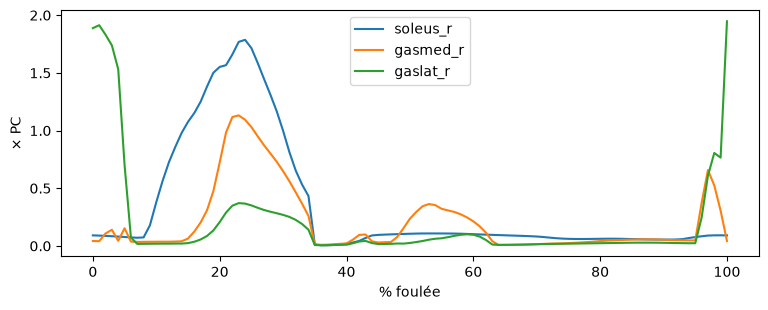

Pic du triceps sural : 3.3 × poids du corps


In [25]:
# ── 4. Forces du triceps sural (× poids du corps)
POIDS = 75.3 * 9.81                 # poids du corps en N (≈ 738,7 N)
a, b = contacts[1], contacts[2]     # la foulée (2e → 3e contact droit)
pct = np.linspace(0, 100, 101)

plt.figure(figsize=(9, 3.2))
for m in ["soleus_r", "gasmed_r", "gaslat_r"]:
    plt.plot(pct, normaliser(frc.time, frc[m], a, b) / POIDS, label=m)   # ← 4 espaces devant
plt.legend(); plt.xlabel("% foulée"); plt.ylabel("× PC"); plt.show()

tri = normaliser(frc.time, frc.soleus_r + frc.gasmed_r + frc.gaslat_r, a, b) / POIDS
print(f"Pic du triceps sural : {tri.max():.1f} × poids du corps")






[error] Model unable to assemble: AssemblySolver::assemble() Failed: SimTK Exception thrown at Assembler.cpp:897:
  Method Assembler::assemble() failed because:
Unable to achieve required assembly error tolerance.
Assembly error tolerance achieved: 9.6025685138172016e-09 required: 1e-10..Model relaxing constraints and trying again.


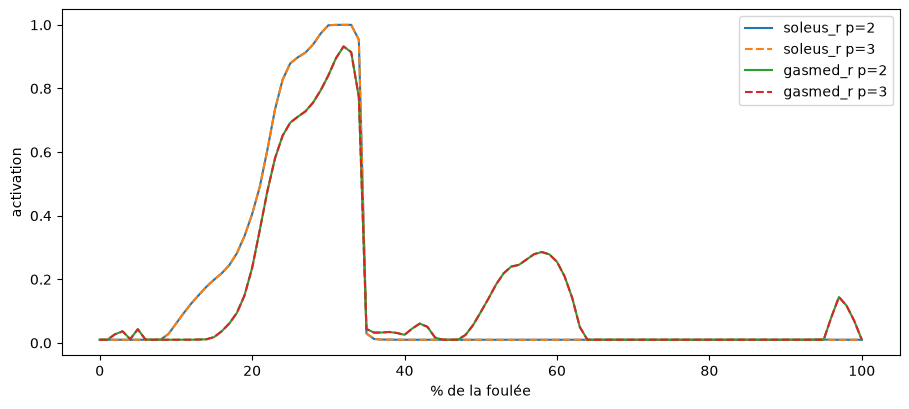

In [26]:
# --5. Sensibilité au critère : exposant 2 vs 3
so3 = osim.AnalyzeTool("Course_Setup_SO.xml")
so3.setName("SO_p3")

# on convertir l'analyse en staticoptimisation
osim.StaticOptimization.safeDownCast(so3.getAnalysisSet().get(0)).setActivationExponent(3)
so3.run()

act3 = lire_sto("resultats_SO/SO_p3_StaticOptimization_activation.sto")
plt.figure(figsize=(9,4))
for m, st in [("soleus_r", "-"), ("gasmed_r", "-")]:
    plt.plot(pct, normaliser(act.time, act[m], a, b), st, label=f"{m} p=2")
    plt.plot(pct, normaliser(act3.time, act3[m], a, b), "--", label=f"{m} p=3")
plt.legend()
plt.tight_layout()
plt.xlabel("% de la foulée")
plt.ylabel("activation")
plt.show()



In [27]:
# Etape 5 => Mise à l'echelle scale 

# --1. Regarder le setup Scale : quelle paires de marqueurs pour quels segments ? 
os.chdir("/Users/lucas1/Desktop/Formation_OpenSim/05_scaling")
print(os.path.exists("Sujet02_Setup_Scale.xml"))     # doit afficher True

st = osim.ScaleTool("Sujet02_Setup_Scale.xml")
ms = st.getModelScaler().getMeasurementSet()
for i in range(ms.getSize()):
    m = ms.get(i)
    paires = [f"{m.getMarkerPairSet().get(k).getMarkerName(0)}-{m.getMarkerPairSet().get(k).getMarkerName(1)}" for k in range(m.getMarkerPairSet().getSize())]
    corps = [m.getBodyScaleSet().get(k).getName() for k in range(m.getBodyScaleSet().getSize())]
    print(f"{m.getName():14s} paires {paires} => {corps}")
print("Masse du sujet :", st.getSubjectMass(), "kg")

True
bassin         paires ['RASI-LASI', 'RPSI-LPSI', 'RASI-RPSI', 'LASI-LPSI'] => ['pelvis']
cuisse_r       paires ['RASI-RLFC', 'RASI-RMFC'] => ['femur_r', 'patella_r']
cuisse_l       paires ['LASI-LLFC', 'LASI-LMFC'] => ['femur_l', 'patella_l']
jambe_r        paires ['RLFC-RLMAL', 'RMFC-RMMAL'] => ['tibia_r']
jambe_l        paires ['LLFC-LLMAL', 'LMFC-LMMAL'] => ['tibia_l']
pied_r         paires ['RCAL-RTOE', 'RCAL-RMT5'] => ['talus_r', 'calcn_r', 'toes_r']
pied_l         paires ['LCAL-LTOE', 'LCAL-LMT5'] => ['talus_l', 'calcn_l', 'toes_l']
tronc          paires ['C7-CLAV', 'RACR-LACR'] => ['torso']
bras_r         paires ['RACR-RLEL', 'RACR-RMEL'] => ['humerus_r']
bras_l         paires ['LACR-LLEL', 'LACR-LMEL'] => ['humerus_l']
avant_bras_r   paires ['RLEL-RFAradius', 'RMEL-RFAulna'] => ['ulna_r', 'radius_r', 'hand_r']
avant_bras_l   paires ['LLEL-LFAradius', 'LMEL-LFAulna'] => ['ulna_l', 'radius_l', 'hand_l']
Masse du sujet : 82.0 kg


In [28]:
# -- 2. Mise à l'echelle pour le sujet 02
st.run()
print(os.path.exists("Sujet02_scaled.osim"))

True


In [33]:
# --- 3. Contrôle qualité : erreur des marqueurs sur la pose statique
ik = osim.InverseKinematicsTool()
ik.setName("Statique")
ik.set_model_file("Sujet02_scaled.osim")
ik.setMarkerDataFileName("Sujet02_statique.trc")
ik.setStartTime(0.5); ik.setEndTime(1.5)
ik.setOutputMotionFileName("Sujet02_statique_IK.mot")
ik.set_report_errors(True); ik.set_results_directory("resultats_IK")

t, noms, _ = lire_trc("Sujet02_statique.trc")
for n in noms:
    tk = osim.IKMarkerTask()
    tk.setName(n)
    tk.setApply(True); tk.setWeight(1.0)
    ik.getIKTaskSet().cloneAndAppend(tk)

ik.run()

e = lire_sto("resultats_IK/Statique_ik_marker_errors.sto")
print(f"RMS {e.marker_error_RMS.mean()*1000:.1f} mm | max {e.marker_error_max.max()*1000:.1f} mm")


               MODEL: Sujet02
         coordinates: 39
              forces: 97
           actuators: 97
             muscles: 80
            analyses: 0
              probes: 0
              bodies: 22
              joints: 22
         constraints: 2
             markers: 54
         controllers: 0
  contact geometries: 0
misc modelcomponents: 0
RMS 1.6 mm | max 4.0 mm


In [36]:
# ── 4. Vérification : comparer les longueurs de segments au « vrai » sujet
def longueur_femur(chemin):
    m = osim.Model(chemin)
    s = m.initSystem()
    h = m.getBodySet().get("femur_r").getPositionInGround(s) # origine du fémur = centre de hanche
    g = m.getBodySet().get("tibia_r").getPositionInGround(s) # origine du tibia = genou
    return np.linalg.norm([h.get(k) - g.get(k) for k in range(3)])
for f in ["Rajagopal2016.osim", "Sujet02_scaled.osim", "verite/Sujet02_vrai.osim"]:
    m = osim.Model(f); s = m.initSystem()
print(f"{f:28s} masse {m.getTotalMass(s):5.1f} kg | fémur {longueur_femur(f)*100:5.1f} cm")

verite/Sujet02_vrai.osim     masse  82.0 kg | fémur  43.7 cm


In [47]:
# Etape 6 : Mini projet sujet 02

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import opensim as osim 

DOSSIER = "/Users/lucas1/Desktop/Formation_OpenSim/07_projet_sujet02"
os.chdir(DOSSIER)

from outils_opensim import *    # lire_sto, lire_trc, normaliser...

osim.Logger.setLevelString("error")
osim.Logger.addFileSink("opensim.log.txt")     # à lire si le noyeau meurt 

print("OpenSim", osim.GetVersion(), "| dossier:", os.getcwd())
print(sorted(os.listdir()))








OpenSim 4.6-2026-06-22-85aaf64 | dossier: /Users/lucas1/Desktop/Formation_OpenSim/07_projet_sujet02
['07_projet_sujet02_EXERCICES.ipynb', '07_projet_sujet02_SOLUTIONS.ipynb', 'Rajagopal2016.osim', 'Sujet02_Course_ExternalLoads.xml', 'Sujet02_Course_GRF.mot', 'Sujet02_Course_Reserves.xml', 'Sujet02_Course_Setup_ID.xml', 'Sujet02_Course_Setup_IK.xml', 'Sujet02_Course_Setup_SO.xml', 'Sujet02_Course_marqueurs.trc', 'Sujet02_Setup_Scale.xml', 'Sujet02_statique.trc', 'outils_opensim.py', 'sujet01_flexions_moyennes.csv', 'verite']


In [51]:
# Mise à l'echelle, Scale 
st = osim.ScaleTool("Sujet02_Setup_Scale.xml")
print("Masse du sujet :", st.getSubjectMass(), "kg")
st.run()
print("Modèle mis à l'échelle crée :", os.path.exists("Sujet02_scaled.osim"))

Masse du sujet : 82.0 kg
Modèle mis à l'échelle crée : True


In [52]:
# Cinématique inverse et contrôle qualité 
ik = osim.InverseKinematicsTool("Sujet02_Course_Setup_IK.xml")
print("Modèle utilisé :", ik.get_model_file())
print("Marqueurs :", ik.getMarkerDataFileName())
ik.run()


Modèle utilisé : Sujet02_scaled.osim
Marqueurs : Sujet02_Course_marqueurs.trc

               MODEL: Sujet02
         coordinates: 39
              forces: 97
           actuators: 97
             muscles: 80
            analyses: 0
              probes: 0
              bodies: 22
              joints: 22
         constraints: 2
             markers: 54
         controllers: 0
  contact geometries: 0
misc modelcomponents: 0


True

In [53]:
print(os.listdir("resultats_IK"))
e = lire_sto("resultats_IK/Sujet02_course_IK_ik_marker_errors.sto")
print(f"IK : RMS {e.marker_error_RMS.mean()*1000:.1f} mm | max {e.marker_error_max.max()*1000:.1f} mm")
print("Seuils : RMS < 20mm, max < 40mm")



['Sujet02_Course_IK_ik_marker_errors.sto']
IK : RMS 7.1 mm | max 24.0 mm
Seuils : RMS < 20mm, max < 40mm


In [56]:
# Foulée du pied droit 
grf = lire_sto("Sujet02_Course_GRF.mot")
contacts, decollages = evenements(grf, "r")
foulees = list(zip(contacts[:-1], contacts[1:]))
print("Contacts :", np.round(contacts,2))
print("Nombre de foulées :", len(foulees))

ang  = lire_sto("Sujet02_Course_IK.mot")
pct = np.linspace(0, 100, 101)
articulations = ["hip_flexion_r", "knee_angle_r", "ankle_angle_r"]

moy, ect = {}, {}
for c in articulations:
    courbes = np.array([normaliser(ang.time, ang[c], a, b) for a, b in foulees])
    moy[c] = courbes.mean(axis=0)
    ect[c] = courbes.std(axis=0)



Contacts : [0.04 0.7  1.4  2.1 ]
Nombre de foulées : 3
